In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from umap import UMAP

In [2]:
df_HHZ_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2022.parquet")
df_HHZ_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2023.parquet")
df_HHZ_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2024.parquet")
df_HHZ_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2025.parquet")

df_HHZ = pd.concat([df_HHZ_2022, df_HHZ_2023, df_HHZ_2024, df_HHZ_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHZ.shape}")

Combined dataset shape: (64382, 1238)


In [3]:
df_HHE_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2022.parquet")
df_HHE_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2023.parquet")
df_HHE_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2024.parquet")
df_HHE_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2025.parquet")

df_HHE = pd.concat([df_HHE_2022, df_HHE_2023, df_HHE_2024, df_HHE_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHE.shape}")

Combined dataset shape: (40940, 1238)


In [4]:
df_HHN_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2022.parquet")
df_HHN_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2023.parquet")
df_HHN_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2024.parquet")
df_HHN_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2025.parquet")

df_HHN = pd.concat([df_HHN_2022, df_HHN_2023, df_HHN_2024, df_HHN_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHN.shape}")

Combined dataset shape: (44135, 1238)


In [5]:
HHZ_PATH = Path("TERZ_HHZ_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25")
HHN_PATH = Path("TERZ_HHN_ont25/TERZ_HHN_spectrograms_matrix_results_cut_hw6_ont25")
HHE_PATH = Path("TERZ_HHE_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25")

In [6]:
df = pd.concat([df_HHZ, df_HHE, df_HHN], ignore_index=True)
print(f"All directions combined: {df.shape}")

print("\nTriggers per direction and year")
print(pd.crosstab(df["channel"], df["year"], margins=True, margins_name="total").to_string())

All directions combined: (149457, 1238)

Triggers per direction and year
year      2022   2023   2024   2025   total
channel                                    
HHE      12850  10482  11298   6310   40940
HHN      14606  11116  12235   6178   44135
HHZ      21251  15582  17356  10193   64382
total    48707  37180  40889  22681  149457


In [7]:
feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

# the three directions must have the same feature_* columns, otherwise the concat above fills the gaps with NaN
for name, d in (("HHZ", df_HHZ), ("HHE", df_HHE), ("HHN", df_HHN)):
    if set(col for col in d.columns if col.startswith("feature_")) != set(feature_columns):
        raise ValueError(f"{name} has different feature_* columns than the other directions.")

X = df[feature_columns].to_numpy(dtype=np.float64)
if np.isnan(X).any():
    raise ValueError("NaN found in the feature matrix.")

print(f"Feature matrix: X.shape = {X.shape}")

Feature matrix: X.shape = (149457, 1230)


In [8]:
X_max = X.max(axis=1, keepdims=True)
X_norm = X / X_max
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (149457, 1230)


In [9]:
RANDOM_STATE = 42
METRIC = "euclidean"
PERPLEXITY = 400   #first attempt: sqrt(N), N = triggers of the three directions
EARLY_EXAGGERATION = 14
print(f"N = {X_scaled.shape[0]} -> PERPLEXITY = {PERPLEXITY}")

N = 149457 -> PERPLEXITY = 400


In [10]:
CACHE_DIR = Path("TERZ_all_directions_embeddings_cache")      
CACHE_DIR.mkdir(exist_ok=True)

In [11]:
FORCE_RECOMPUTE = False   # True = ignore the cache and recompute (the cache file is overwritten)

def load_or_compute(cache_path, compute_fn, n_rows, force=False):
    """Load a cached (n_rows, 2) embedding if there is one, otherwise compute it and save it."""
    if cache_path.exists() and not force:
        emb = np.load(cache_path)
        if emb.shape == (n_rows, 2):
            print(f"[cache] loaded {cache_path.name}")
            return emb
        print(f"[cache] {cache_path.name} has shape {emb.shape}, expected ({n_rows}, 2) -> recomputing")
    print(f"[cache] no valid cache for {cache_path.name} -> computing")
    emb = compute_fn()
    tmp = cache_path.with_suffix(".tmp.npy")   # write to a temp file first, so an interrupted run leaves no broken cache
    np.save(tmp, emb)
    tmp.replace(cache_path)
    print(f"[cache] saved {cache_path.name}")
    return emb

In [12]:
tag = f"tsne_perp{PERPLEXITY}_ee{EARLY_EXAGGERATION}_{METRIC}_rs{RANDOM_STATE}"
tsne_cache = CACHE_DIR / f"TERZ_hw6_ont25_all_directions_{tag}.npy"


def run_tsne():
    tsne = TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE, metric=METRIC)
    return tsne.fit_transform(X_scaled)


X_tsne = load_or_compute(tsne_cache, run_tsne, n_rows=len(X_scaled), force=FORCE_RECOMPUTE)

[cache] loaded TERZ_hw6_ont25_all_directions_tsne_perp400_ee14_euclidean_rs42.npy


In [13]:
df_tSNE = pd.DataFrame(X_tsne, columns=['tSNE_1', 'tSNE_2'])
df_tSNE.insert(loc=0, column='year', value=df['year'])
df_tSNE.insert(loc=1, column='station', value=df['station'])
df_tSNE.insert(loc=2, column='channel', value=df['channel'])
df_tSNE.insert(loc=3, column='file', value=df['file'])
df_tSNE.insert(loc=4, column='date', value=df['date'])
df_tSNE.insert(loc=5, column='month_year', value=df['month_year'])
df_tSNE.insert(loc=6, column='trigger_time', value=df['trigger_time'])
df_tSNE.insert(loc=7, column='q_value', value=df['q_value'])

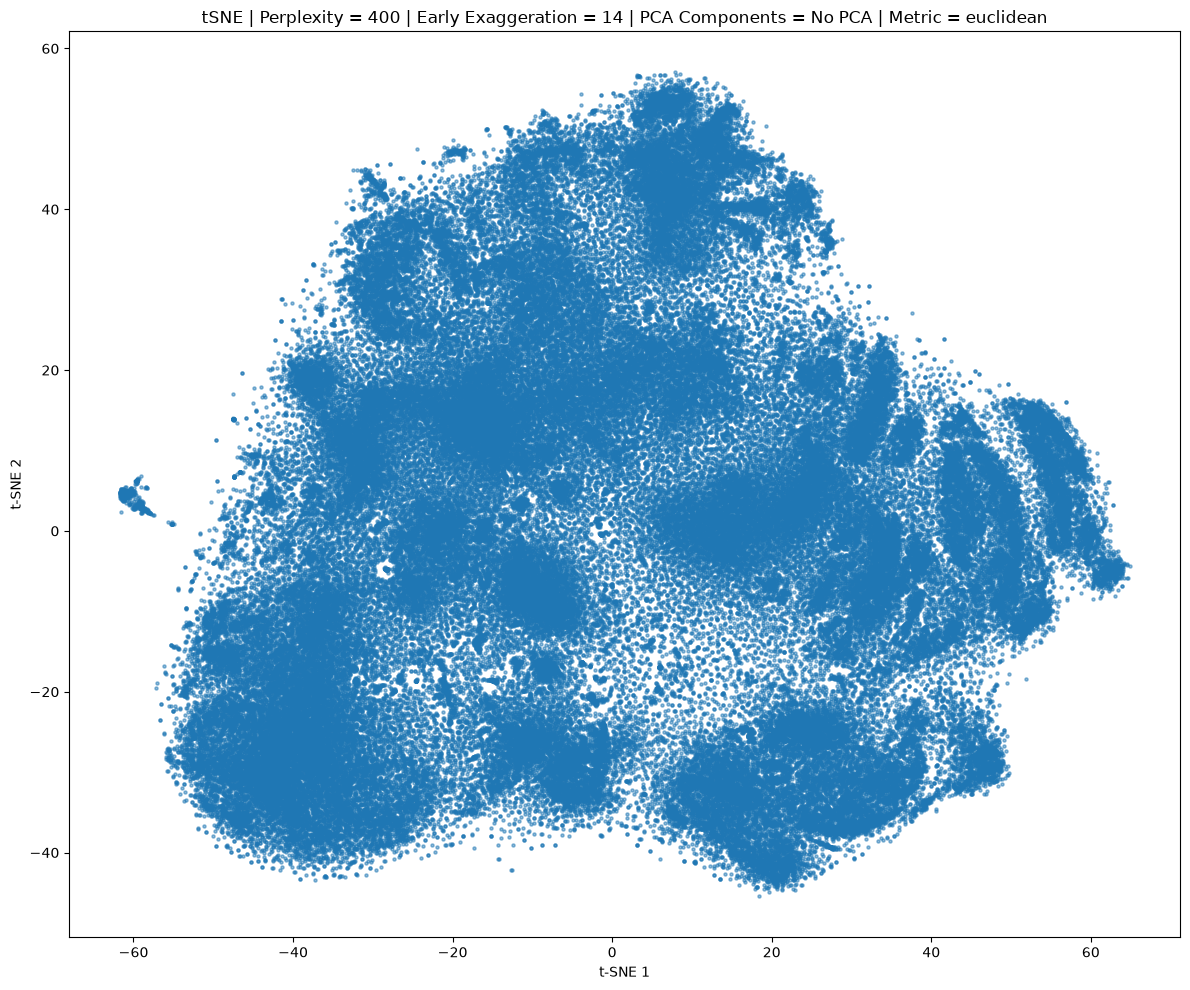

In [14]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"tSNE | Perplexity = {PERPLEXITY} | Early Exaggeration = {EARLY_EXAGGERATION} | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

In [15]:
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1

In [16]:
tag = f"umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}_{METRIC}_rs{RANDOM_STATE}"
umap_cache = CACHE_DIR / f"TERZ_hw6_ont25_all_directions_{tag}.npy"


def run_umap():
    reducer = UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                   metric=METRIC, random_state=RANDOM_STATE)
    return reducer.fit_transform(X_scaled)


X_umap = load_or_compute(umap_cache, run_umap, n_rows=len(X_scaled), force=FORCE_RECOMPUTE)

[cache] loaded TERZ_hw6_ont25_all_directions_umap_nn15_md0.1_euclidean_rs42.npy


In [17]:
df_umap = pd.DataFrame(X_umap, columns=['umap_1', 'umap_2'])
df_umap.insert(loc=0, column='year', value=df['year'])
df_umap.insert(loc=1, column='station', value=df['station'])
df_umap.insert(loc=2, column='channel', value=df['channel'])
df_umap.insert(loc=3, column='file', value=df['file'])
df_umap.insert(loc=4, column='date', value=df['date'])
df_umap.insert(loc=5, column='month_year', value=df['month_year'])
df_umap.insert(loc=6, column='trigger_time', value=df['trigger_time'])
df_umap.insert(loc=7, column='q_value', value=df['q_value'])

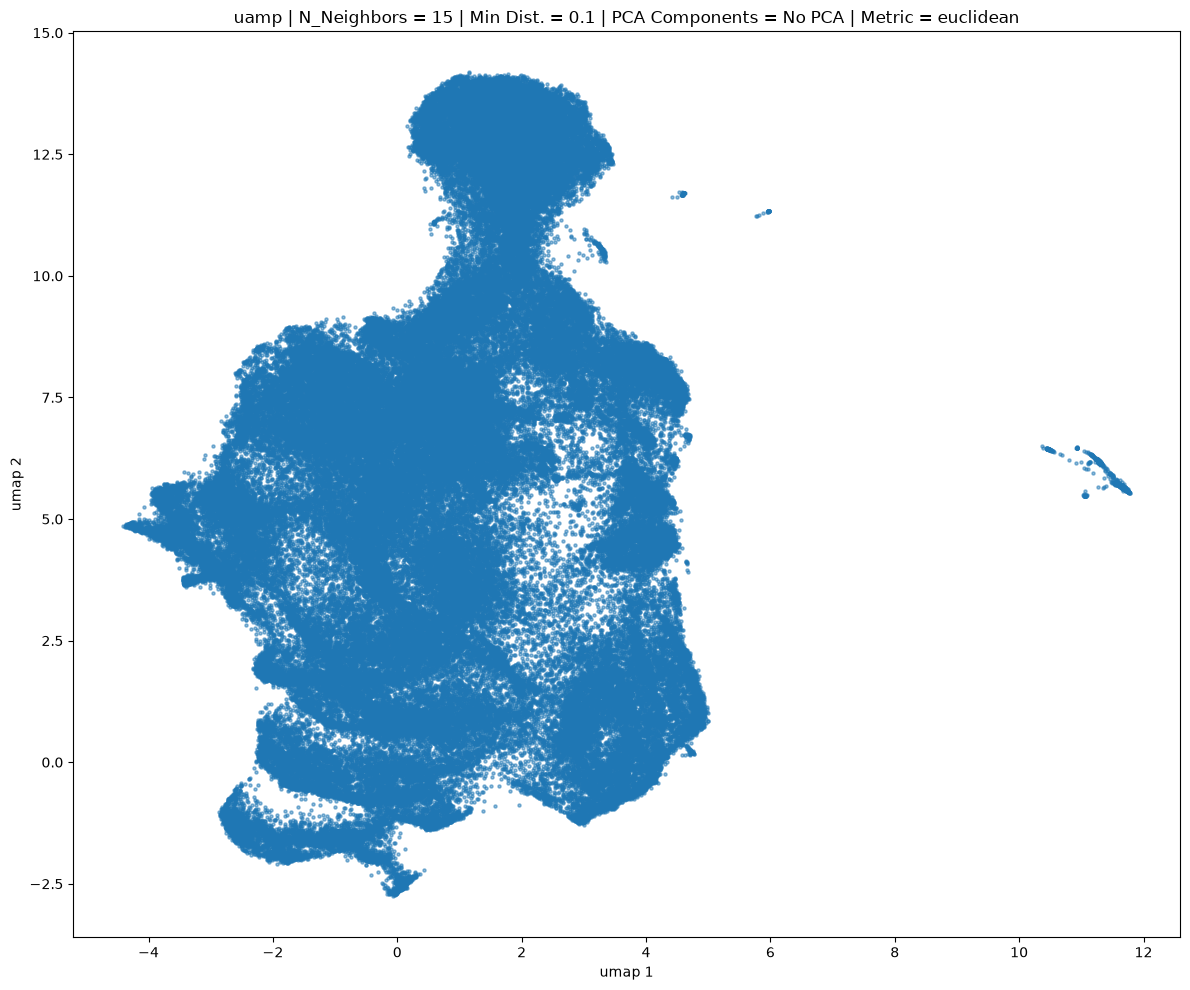

In [18]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_umap[:, 0], X_umap[:, 1],s=5,alpha=0.5)
ax.set_title(f"uamp | N_Neighbors = {UMAP_N_NEIGHBORS} | Min Dist. = {UMAP_MIN_DIST} | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("umap 1")
ax.set_ylabel("umap 2")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.cluster import HDBSCAN

In [19]:
EMBEDDING_FOR_CLASSES = "tsne"     # "tsne" or "umap"
HDBSCAN_MIN_CLUSTER_SIZE = 750
HDBSCAN_MIN_SAMPLES = 200

In [22]:
if EMBEDDING_FOR_CLASSES == "tsne":
    E, df_emb, emb_name = X_tsne, df_tSNE, "t-SNE"
elif EMBEDDING_FOR_CLASSES == "umap":
    E, df_emb, emb_name = X_umap, df_umap, "UMAP"
else:
    raise ValueError("EMBEDDING_FOR_CLASSES must be 'tsne' or 'umap'")

hdb = HDBSCAN(min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE, min_samples=HDBSCAN_MIN_SAMPLES)
labels = hdb.fit_predict(E)              # -1 = noise
df_emb["hdbscan_class"] = labels

n_classes = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print(f"HDBSCAN on {emb_name}: {n_classes} classes, noise = {n_noise} / {len(labels)} ({100 * n_noise / len(labels):.1f}%)")

/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN on t-SNE: 10 classes, noise = 37357 / 149457 (25.0%)


In [23]:
def plot_clusters(ax, E, labels, title, xlabel, ylabel):
    noise = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    ax.scatter(E[noise, 0], E[noise, 1], c="lightgray", s=8, alpha=0.5, label="noise")
    ax.scatter(E[~noise, 0], E[~noise, 1], c=labels[~noise], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"{title}\n{n_clusters} clusters, {noise.sum()} noise points")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if noise.any():
        ax.legend(loc="best", markerscale=2)
    return n_clusters, int(noise.sum())

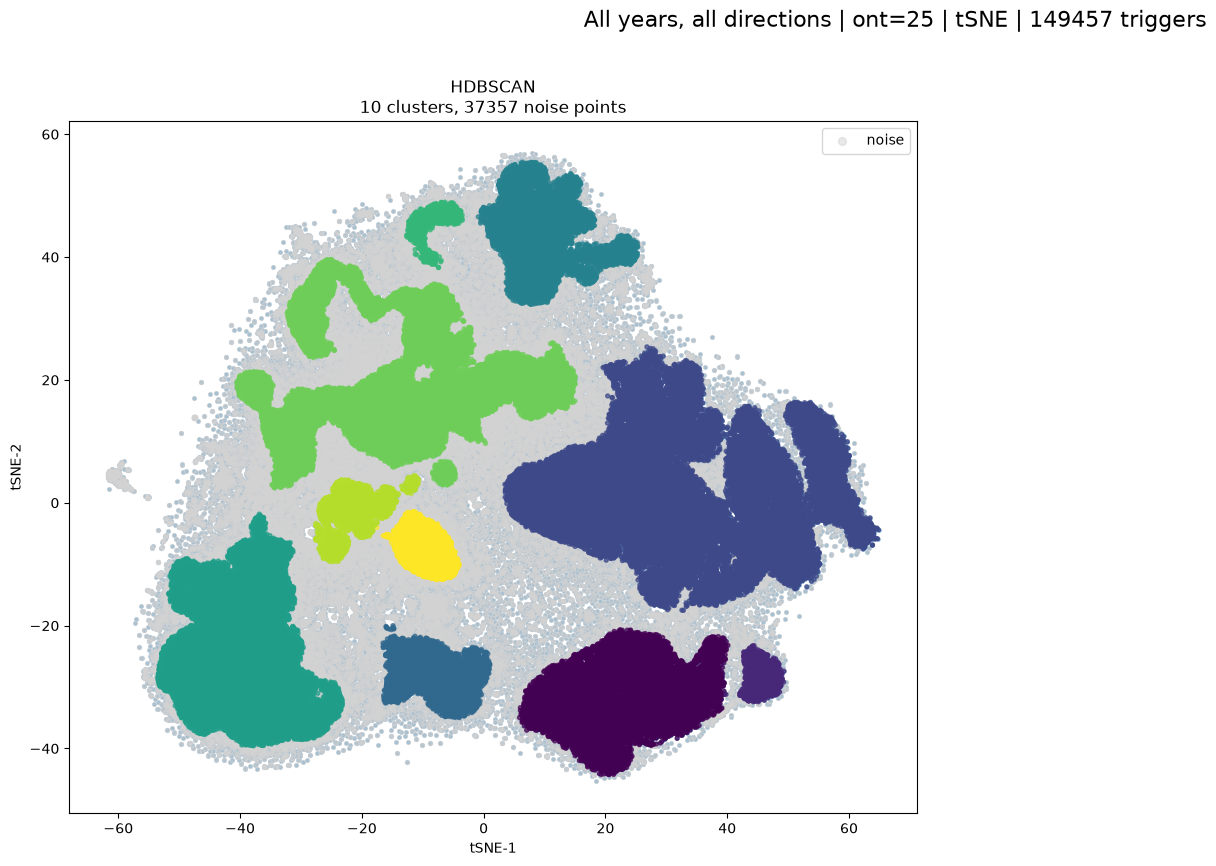

In [24]:
fig = plt.figure(figsize=(18, 16))

ax = fig.add_subplot(2, 2, 1)
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], s=5, alpha=0.5)
n_hdb, noise_hdb = plot_clusters(ax, E, labels, "HDBSCAN", "tSNE-1", "tSNE-2")
fig.suptitle(f"All years, all directions | ont=25 | tSNE | {E.shape[0]} triggers", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

In [25]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
from PIL import Image

In [26]:
# direction (value of the "channel" column) -> folder that contains its qtransform PDFs (the paths are defined at the top of the notebook)
RESULTS_ROOTS = {"HHZ": HHZ_PATH, "HHE": HHE_PATH, "HHN": HHN_PATH}
_unknown = set(df["channel"].unique()) - set(RESULTS_ROOTS)
if _unknown:
    raise ValueError(f"No qtransform folder for channel(s) {sorted(_unknown)}: add them to RESULTS_ROOTS.")
PDF_INDEX_ORDER = "df"
N_THUMBS_PER_CLASS = 30
MIN_DIST_FRAC = 0.04       # minimum distance between two thumbnails, as a fraction of the plot span
THUMB_PX = 120             # width in pixels of each rendered thumbnail
THUMB_ZOOM = 0.35          # size of the thumbnails on the figure
THUMB_SEED = 0

In [27]:
DAY_KEY = ["station", "channel", "date"]
if PDF_INDEX_ORDER == "df":
    df_emb["pdf_index"] = df_emb.groupby(DAY_KEY, sort=False).cumcount()
elif PDF_INDEX_ORDER == "time":
    _t = pd.to_datetime(df_emb["trigger_time"], utc=True)
    df_emb["pdf_index"] = df_emb.assign(_t=_t).groupby(DAY_KEY, sort=False)["_t"].rank(method="first").astype(int) - 1
else:
    raise ValueError("PDF_INDEX_ORDER must be 'df' or 'time'")


def qtransform_pdf_path(row):
    """Path of the qtransform PDF of one row of df_emb.
    Layout: <RESULTS_ROOTS[channel]>/<year>/<station>/<channel>/<month_year>/qtransform_<YYYYMMDD>_<pdf_index, 6 digits>.pdf"""
    day = pd.to_datetime(row["date"]).strftime("%Y%m%d")
    return (RESULTS_ROOTS[str(row["channel"])] / str(row["year"]) / str(row["station"]) / str(row["channel"])
            / str(row["month_year"]) / f"qtransform_{day}_{int(row['pdf_index']):06d}.pdf")


# quick check of the path rule, per direction
for ch in sorted(RESULTS_ROOTS):
    _rows = df_emb[df_emb["channel"] == ch]
    _sample = _rows.sample(min(20, len(_rows)), random_state=1)
    _found = sum(qtransform_pdf_path(r).exists() for _, r in _sample.iterrows())
    print(f"{ch}: PDF found for {_found} of {len(_sample)} random rows")

HHE: PDF found for 20 of 20 random rows
HHN: PDF found for 20 of 20 random rows
HHZ: PDF found for 20 of 20 random rows


In [28]:
def render_pdf_first_page(path, width_px=THUMB_PX):
    """Page 1 of a PDF as an RGB array. Uses PyMuPDF, pypdfium2 or pdf2image, whichever is installed."""
    try:
        import fitz                                  # PyMuPDF
    except ImportError:
        fitz = None
    if fitz is not None:
        with fitz.open(path) as doc:
            page = doc[0]
            zoom = width_px / page.rect.width
            pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), colorspace=fitz.csRGB, alpha=False)
            return np.asarray(Image.frombytes("RGB", (pix.width, pix.height), pix.samples))
    try:
        import pypdfium2 as pdfium
    except ImportError:
        pdfium = None
    if pdfium is not None:
        pdf = pdfium.PdfDocument(str(path))
        try:
            page = pdf[0]
            return np.asarray(page.render(scale=width_px / page.get_width()).to_pil().convert("RGB"))
        finally:
            pdf.close()
    from pdf2image import convert_from_path
    img = convert_from_path(str(path), dpi=50, first_page=1, last_page=1)[0].convert("RGB")
    return np.asarray(img.resize((width_px, int(img.height * width_px / img.width))))


def pick_thumbnails(E, labels, df_emb, per_class, min_dist_frac, seed):
    """Random points of each class (noise included), spread out so the thumbnails do not pile up.
    Points whose PDF cannot be opened are skipped. Returns a list of (row index, image)."""
    rng = np.random.default_rng(seed)
    En = E / np.ptp(E, axis=0)
    chosen, picks, n_fail = [], [], 0
    for c in np.unique(labels):
        n_taken, fails = 0, 0
        for i in rng.permutation(np.flatnonzero(labels == c)):
            if n_taken >= per_class or fails >= 5 * per_class:
                break
            if chosen and np.hypot(*(En[chosen].T - En[i][:, None])).min() < min_dist_frac:
                continue
            try:
                img = render_pdf_first_page(qtransform_pdf_path(df_emb.iloc[i]))
            except Exception:
                fails += 1
                continue
            chosen.append(i)
            picks.append((i, img))
            n_taken += 1
        n_fail += fails
    if not picks:
        raise RuntimeError("No qtransform PDF could be opened: check RESULTS_ROOT and qtransform_pdf_path().")
    print(f"{len(picks)} thumbnails placed, {n_fail} PDFs skipped (missing or unreadable)")
    return picks

# Balanced Subplot

Classes kept: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | dropped (fewer than 900 points): {}
Subsample: 9000 points -> {0: 900, 1: 900, 2: 900, 3: 900, 4: 900, 5: 900, 6: 900, 7: 900, 8: 900, 9: 900}
[cache] loaded TERZ_hw6_ont25_sub9000_537fdabd_tsne_perp100_ee14_euclidean_rs42.npy
[cache] loaded TERZ_hw6_ont25_sub9000_537fdabd_umap_nn15_md0.1_euclidean_rs42.npy

Directions in the subsample (rows = class)
channel        HHE  HHN  HHZ
hdbscan_class               
0              186  238  476
1              150  141  609
2              260  280  360
3              358  331  211
4              137  243  520
5              464  410   26
6              258  254  388
7              220  222  458
8               35   65  800
9               12   16  872


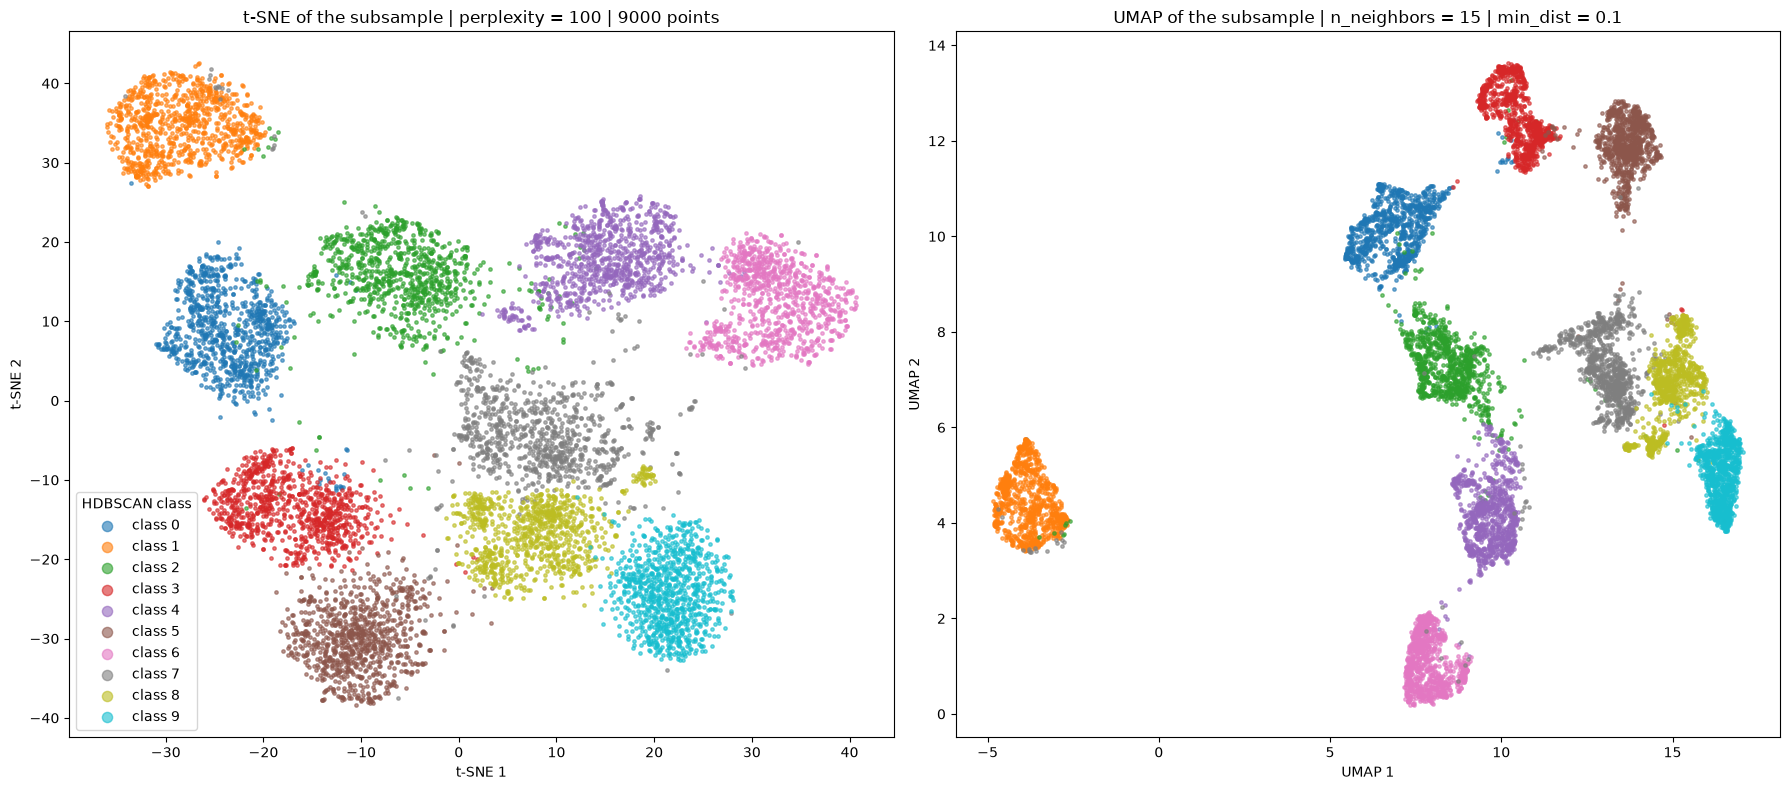

In [29]:
import hashlib

# Settings
PER_CLASS = 900          # points drawn from each class
MIN_CLASS_SIZE = 900     # classes with fewer points are dropped (lower it to keep small classes: they contribute all their points)
SAMPLE_SEED = 42
PERPLEXITY_SUB = 100      # None -> sqrt(number of sampled points), the same rule used for the full set

# 1) Draw PER_CLASS points from every class with at least MIN_CLASS_SIZE points (noise, -1, is left out)
rng = np.random.default_rng(SAMPLE_SEED)
class_sizes = pd.Series(labels[labels != -1]).value_counts().sort_index()
kept = class_sizes[class_sizes >= MIN_CLASS_SIZE].index.tolist()
dropped = class_sizes[class_sizes < MIN_CLASS_SIZE].to_dict()
if not kept:
    raise ValueError(f"No class has at least {MIN_CLASS_SIZE} points (class sizes: {class_sizes.to_dict()})")

idx = np.sort(np.concatenate([rng.choice(np.flatnonzero(labels == c), size=min(PER_CLASS, int(class_sizes.loc[c])), replace=False) for c in kept]))

sub_labels = labels[idx]
n_sub = len(idx)
print(f"Classes kept: {kept} | dropped (fewer than {MIN_CLASS_SIZE} points): {dropped}")
print(f"Subsample: {n_sub} points -> {pd.Series(sub_labels).value_counts().sort_index().to_dict()}")

# 2) New t-SNE and UMAP on the features of the sampled points (same preprocessing as the full set), with the cache
X_sub = X_scaled[idx]
perp_sub = PERPLEXITY_SUB or int(round(np.sqrt(n_sub)))
sub_id = hashlib.md5(idx.tobytes()).hexdigest()[:8]      # changes whenever the sampled points change


def run_tsne_sub():
    return TSNE(n_components=2, perplexity=perp_sub, early_exaggeration=EARLY_EXAGGERATION, init="pca",
                learning_rate="auto", random_state=RANDOM_STATE, metric=METRIC).fit_transform(X_sub)

def run_umap_sub():
    return UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_sub)


tsne_sub_cache = CACHE_DIR / (f"TERZ_hw6_ont25_sub{n_sub}_{sub_id}_tsne_perp{perp_sub}_ee{EARLY_EXAGGERATION}_{METRIC}_rs{RANDOM_STATE}.npy")
umap_sub_cache = CACHE_DIR / (f"TERZ_hw6_ont25_sub{n_sub}_{sub_id}_umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}_{METRIC}_rs{RANDOM_STATE}.npy")
X_tsne_sub = load_or_compute(tsne_sub_cache, run_tsne_sub, n_rows=n_sub, force=FORCE_RECOMPUTE)
X_umap_sub = load_or_compute(umap_sub_cache, run_umap_sub, n_rows=n_sub, force=FORCE_RECOMPUTE)

# 3) Table of the sampled points: metadata + class + the new coordinates (orig_index = row of the full dataset)
df_sub = df_emb.iloc[idx].copy()
df_sub.insert(0, "orig_index", idx)
df_sub["sub_tSNE_1"], df_sub["sub_tSNE_2"] = X_tsne_sub[:, 0], X_tsne_sub[:, 1]
df_sub["sub_umap_1"], df_sub["sub_umap_2"] = X_umap_sub[:, 0], X_umap_sub[:, 1]
df_sub = df_sub.reset_index(drop=True)

print("\nDirections in the subsample (rows = class)")
print(pd.crosstab(df_sub["hdbscan_class"], df_sub["channel"]).to_string())

# 4) Quick look, coloured by HDBSCAN class (same colours as the thumbnail figure)
all_ids = [c for c in np.unique(labels) if c != -1]
cmap = plt.get_cmap("tab10" if len(all_ids) <= 10 else "tab20")
class_color = {c: cmap(k % cmap.N) for k, c in enumerate(all_ids)}

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, E_sub, name in zip(axes, (X_tsne_sub, X_umap_sub), ("t-SNE", "UMAP")):
    for c in kept:
        m = sub_labels == c
        ax.scatter(E_sub[m, 0], E_sub[m, 1], s=6, alpha=0.6, color=class_color[c], label=f"class {c}")
    ax.set_xlabel(f"{name} 1")
    ax.set_ylabel(f"{name} 2")
axes[0].set_title(f"t-SNE of the subsample | perplexity = {perp_sub} | {n_sub} points")
axes[1].set_title(f"UMAP of the subsample | n_neighbors = {UMAP_N_NEIGHBORS} | min_dist = {UMAP_MIN_DIST}")
axes[0].legend(markerscale=3, title="HDBSCAN class")
plt.tight_layout()
plt.show()

# Seismograms of 5 random triggers per class

In [30]:
import subprocess
from obspy import read, UTCDateTime

N_PER_CLASS = 5
INCLUDE_NOISE = False        # True: also plot N_PER_CLASS triggers of the HDBSCAN noise (label -1)
WAVEFORM_SEED = 0
PLOT_HALF_WINDOW = 6         # s: the seismogram is plotted from trigger - 6 s to trigger + 6 s
DOWNLOAD_HALF_WINDOW = 60    # s: window downloaded around the trigger (the extra time is used to demean/detrend)

MSEED_DIR = None             # folder with the local .mseed files (tried before downloading); None -> only the path stored in df_emb["file"]
MSEED_CACHE_DIR = Path("TERZ_trigger_mseed")        # downloaded ±1 min files, reused on the next run
WAVEFORM_FIG_DIR = Path("TERZ_class_waveforms")     # one PNG per class

FDSNWS_FETCH = ["fdsnws_fetch"]   # or e.g. ["python3", "/path/to/fdsnws_fetch.py"]
FDSN_URL = None                   # None -> fdsnws_fetch default; or e.g. "http://eida.knmi.nl"
NETWORK = "*"                     # put the network code here if the wildcard matches more than one network
LOCATION = "*"

In [31]:
def trigger_utc(row):
    """trigger_time of one row of df_emb as an obspy UTCDateTime."""
    ts = pd.to_datetime(row["trigger_time"], utc=True)
    return UTCDateTime(ts.strftime("%Y-%m-%dT%H:%M:%S.%f"))


def download_mseed(station, channel, t0, t1):
    """Download t0..t1 of one channel with fdsnws_fetch (skipped if it is already in MSEED_CACHE_DIR). Returns the file path."""
    fmt = "%Y-%m-%dT%H:%M:%S"
    start, end = t0.strftime(fmt), (t1 + 1).strftime(fmt)      # whole seconds, so the window is up to 1 s larger than asked
    out = MSEED_CACHE_DIR / f"{station}_{channel}_{start.replace(':', '')}_{end.replace(':', '')}.mseed"
    if out.exists() and out.stat().st_size > 0:
        return out
    MSEED_CACHE_DIR.mkdir(exist_ok=True)
    part = out.with_suffix(".part")                            # write to a temp name first, so a failed download leaves no broken file
    cmd = FDSNWS_FETCH + ["-N", NETWORK, "-S", station, "-L", LOCATION, "-C", channel, "-s", start, "-e", end, "-o", str(part)]
    if FDSN_URL:
        cmd += ["-u", FDSN_URL]
    try:
        res = subprocess.run(cmd, capture_output=True, text=True, timeout=300)
    except FileNotFoundError:
        raise FileNotFoundError(f"'{FDSNWS_FETCH[0]}' not found: set FDSNWS_FETCH to the right command or script path")
    if res.returncode != 0 or not part.exists() or part.stat().st_size == 0:
        part.unlink(missing_ok=True)
        raise RuntimeError(f"fdsnws_fetch failed (code {res.returncode}): {res.stderr.strip()[-300:]}")
    part.replace(out)
    return out


def read_window(path, station, channel, t0, t1):
    """t0..t1 of one channel from an .mseed file, as a single trace (None if the file has no such data)."""
    st = read(str(path), starttime=t0, endtime=t1).select(station=station, channel=channel)
    if not st:
        return None
    st = st.select(location=sorted({tr.stats.location for tr in st})[0])    # in case several location codes come back
    st.merge(method=1, fill_value="interpolate")
    return st[0]


def get_seismogram(row):
    """Seismogram of one row of df_emb: demeaned and detrended on the ±DOWNLOAD_HALF_WINDOW window, then cut to
    ±PLOT_HALF_WINDOW around the trigger. Reads the local .mseed file if it can, otherwise downloads the window.
    Returns (trace, trigger time)."""
    t = trigger_utc(row)
    t0, t1 = t - DOWNLOAD_HALF_WINDOW, t + DOWNLOAD_HALF_WINDOW
    station, channel = str(row["station"]), str(row["channel"])

    tr = None
    f = row.get("file")
    if isinstance(f, str) and f:
        for cand in [Path(f)] + ([MSEED_DIR / Path(f).name] if MSEED_DIR else []):
            if cand.is_file():
                try:
                    tr = read_window(cand, station, channel, t0, t1)
                except Exception:
                    tr = None
                if tr is not None:
                    break
    if tr is None:
        tr = read_window(download_mseed(station, channel, t0, t1), station, channel, t0, t1)
    if tr is None:
        raise RuntimeError("no data for this channel and time")

    tr = tr.copy().trim(t0, t1)
    tr.data = tr.data.astype(np.float64)
    tr.detrend("demean")
    tr.detrend("linear")
    tr.trim(t - PLOT_HALF_WINDOW, t + PLOT_HALF_WINDOW)
    tol = 2 * tr.stats.delta
    if tr.stats.starttime > t - PLOT_HALF_WINDOW + tol or tr.stats.endtime < t + PLOT_HALF_WINDOW - tol:
        raise RuntimeError(f"the data do not cover the whole ±{PLOT_HALF_WINDOW} s window (gap?)")
    return tr, t

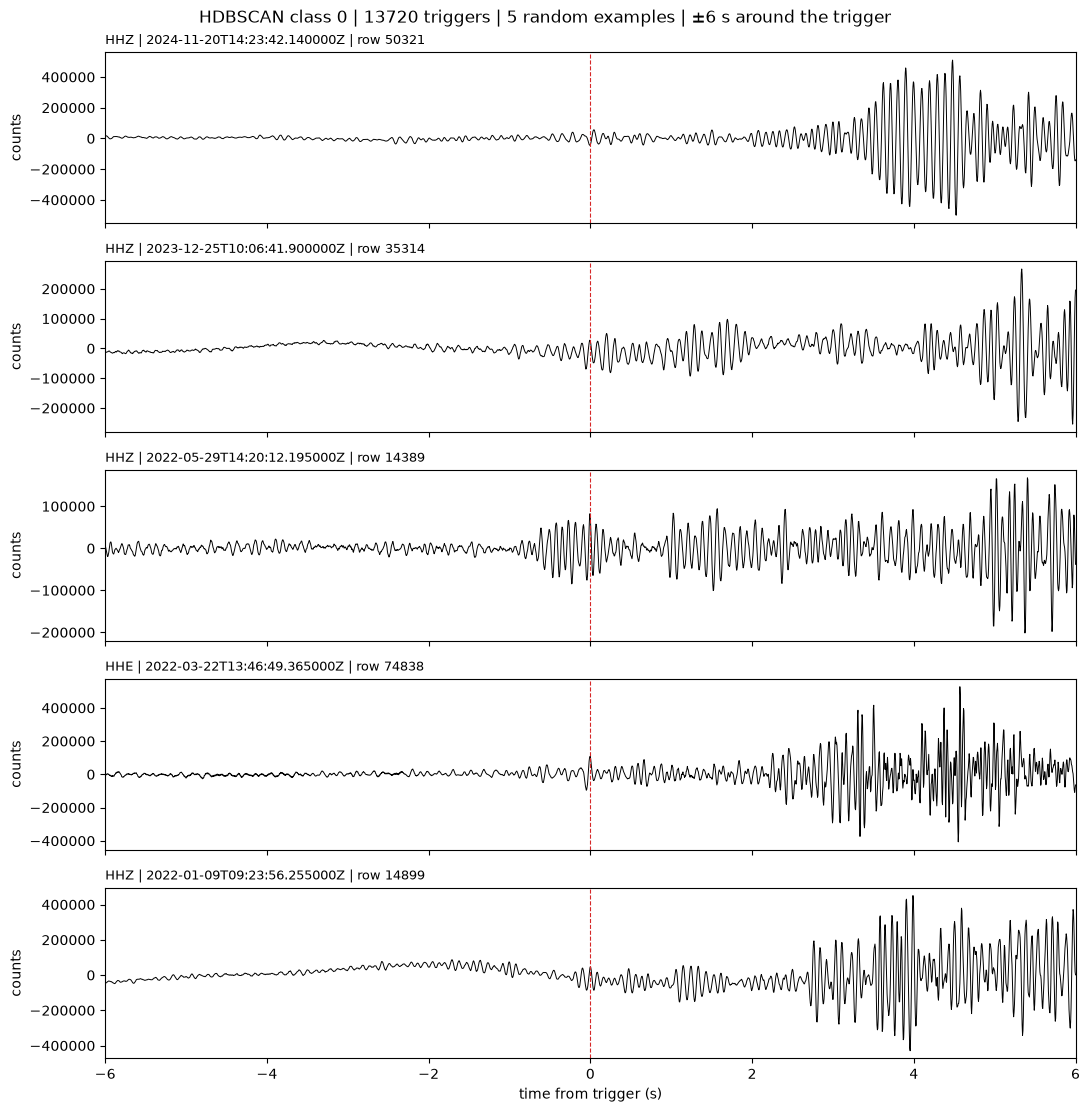

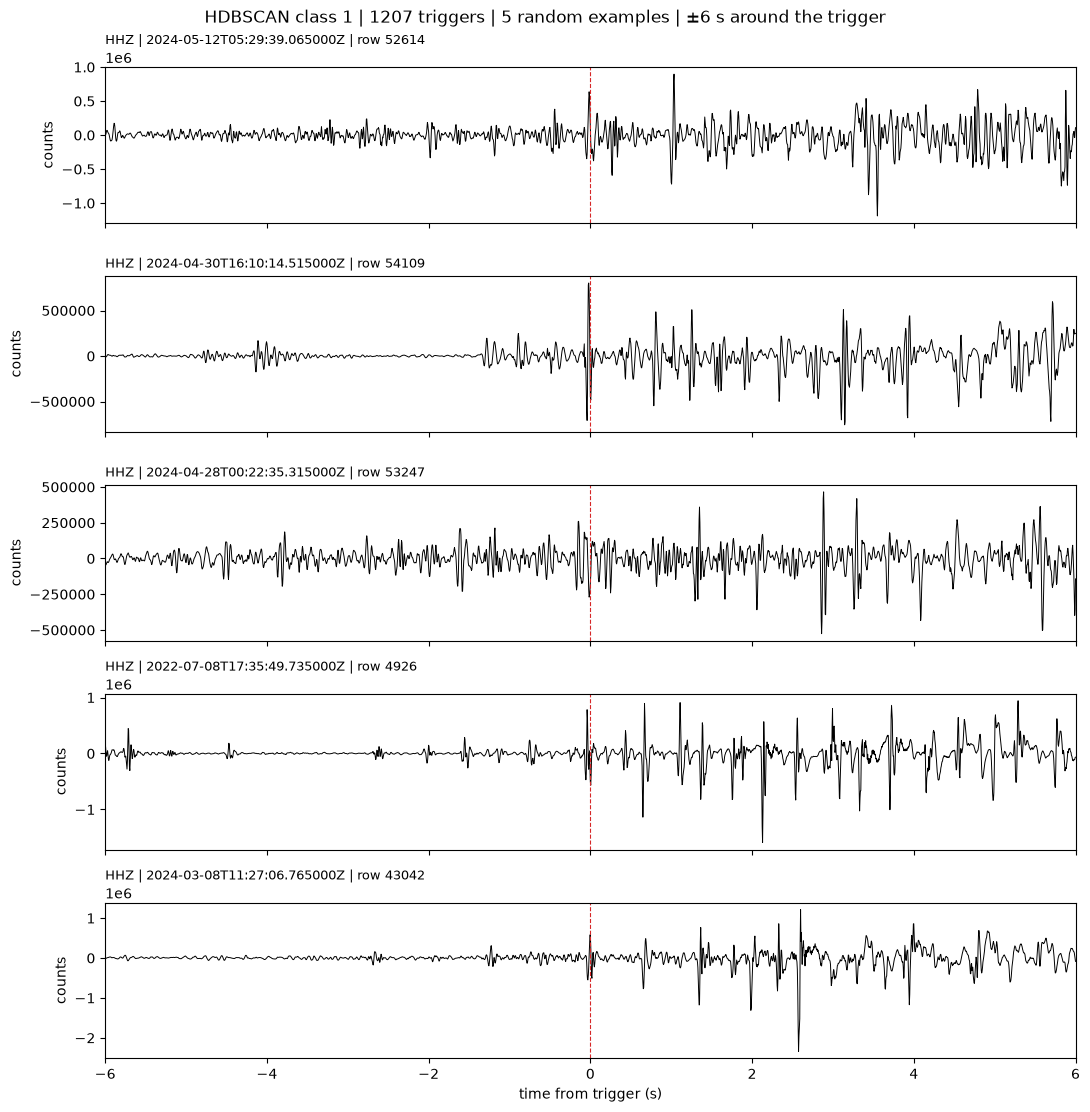

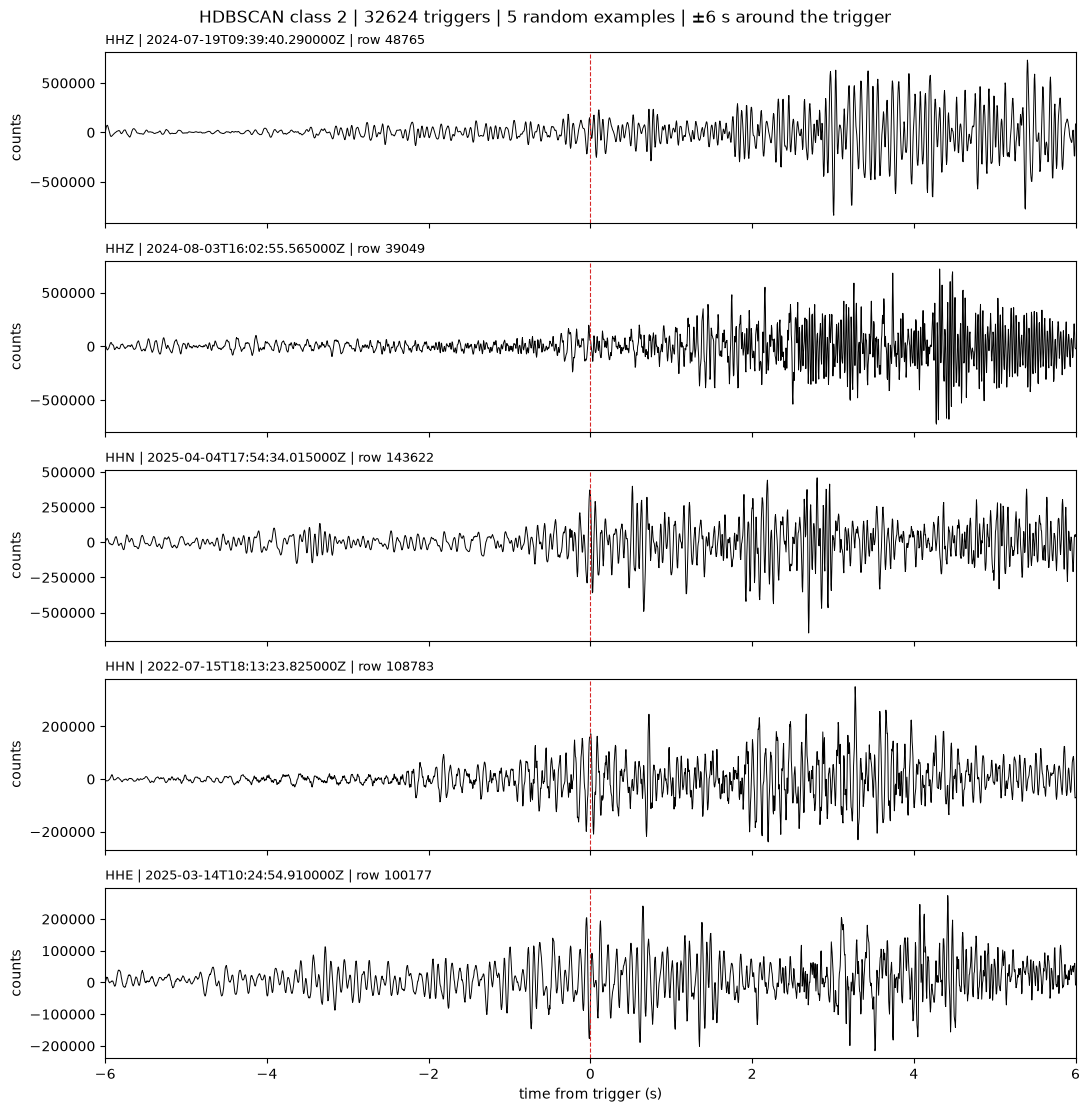

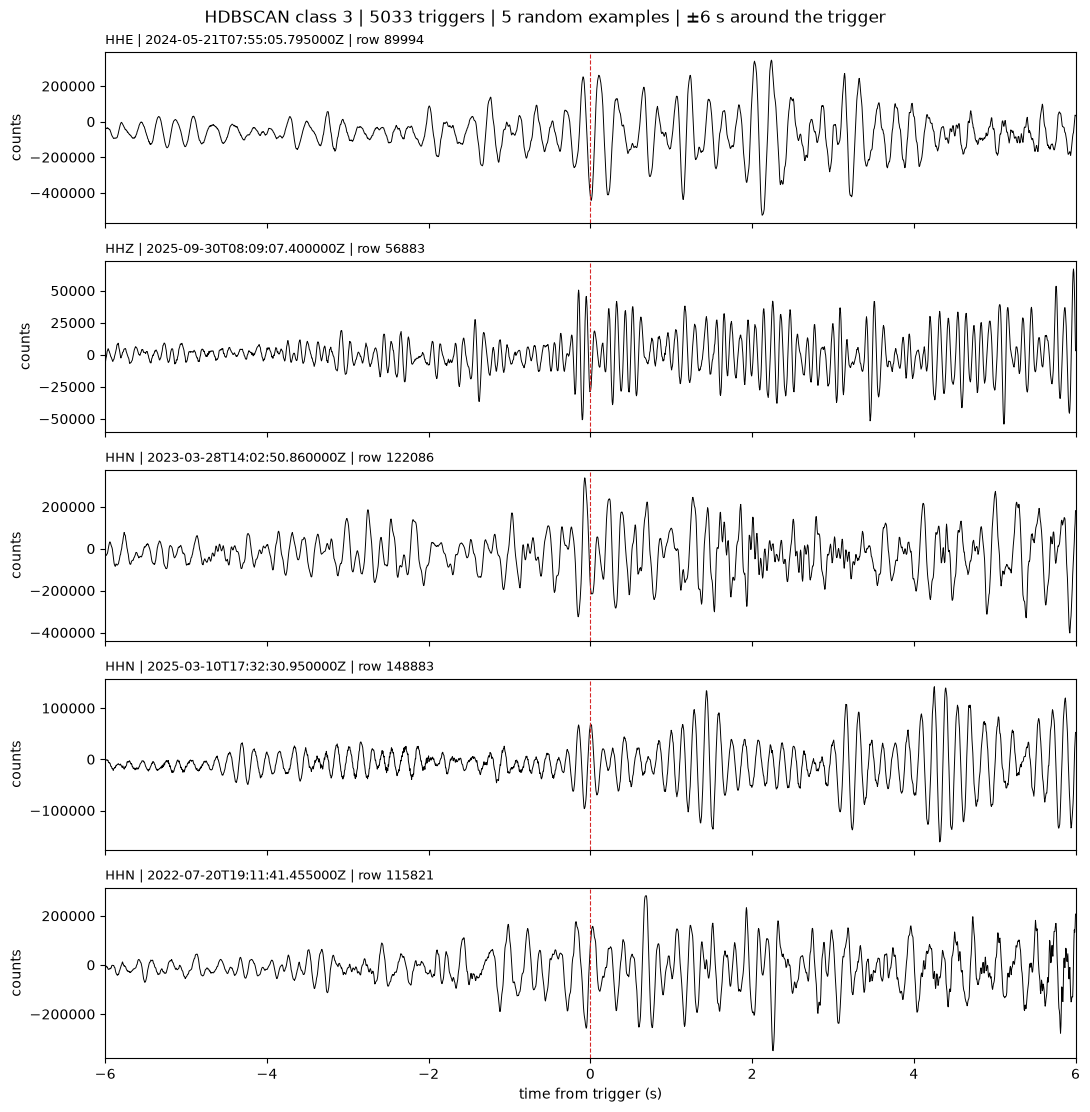

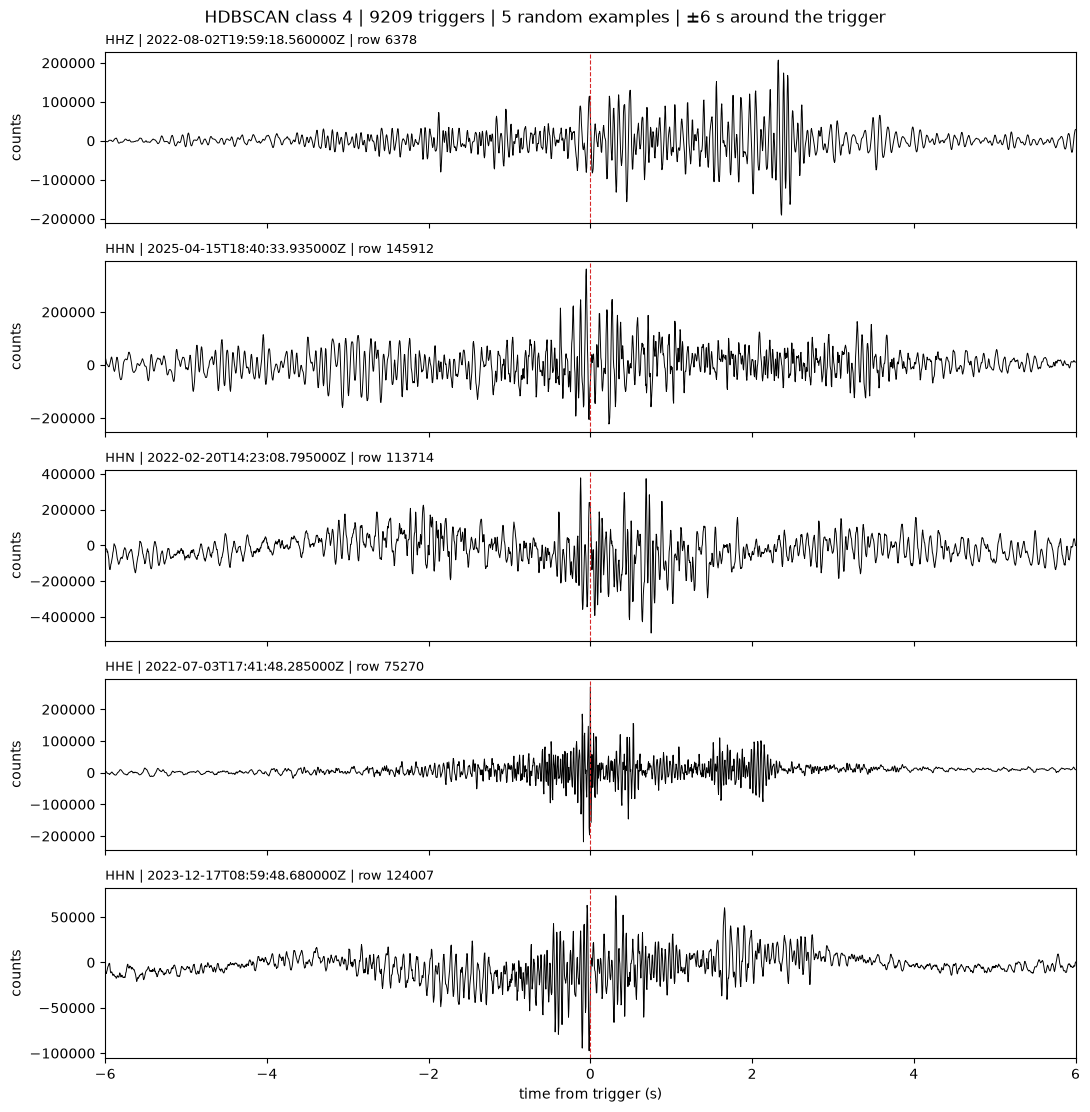

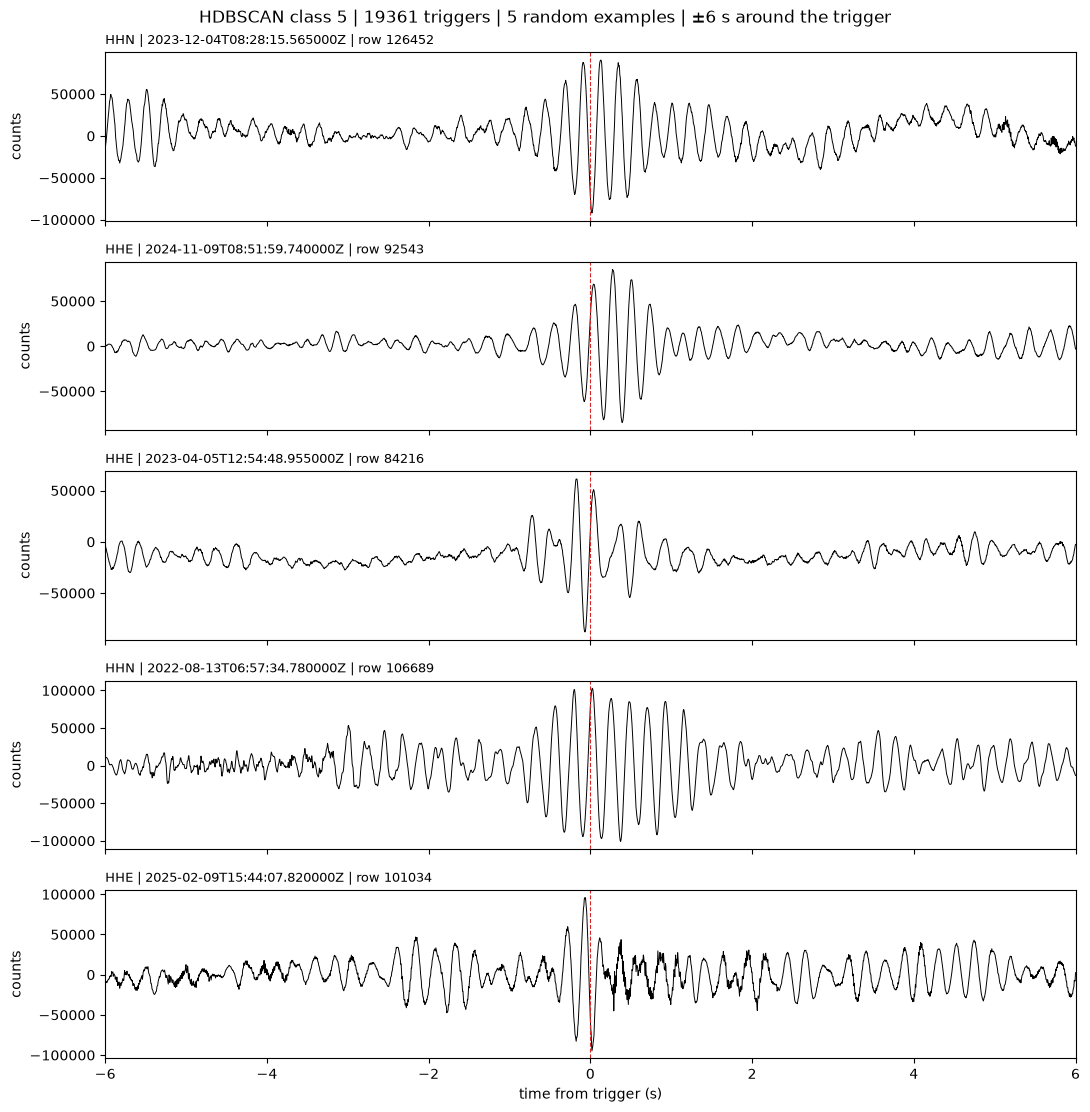

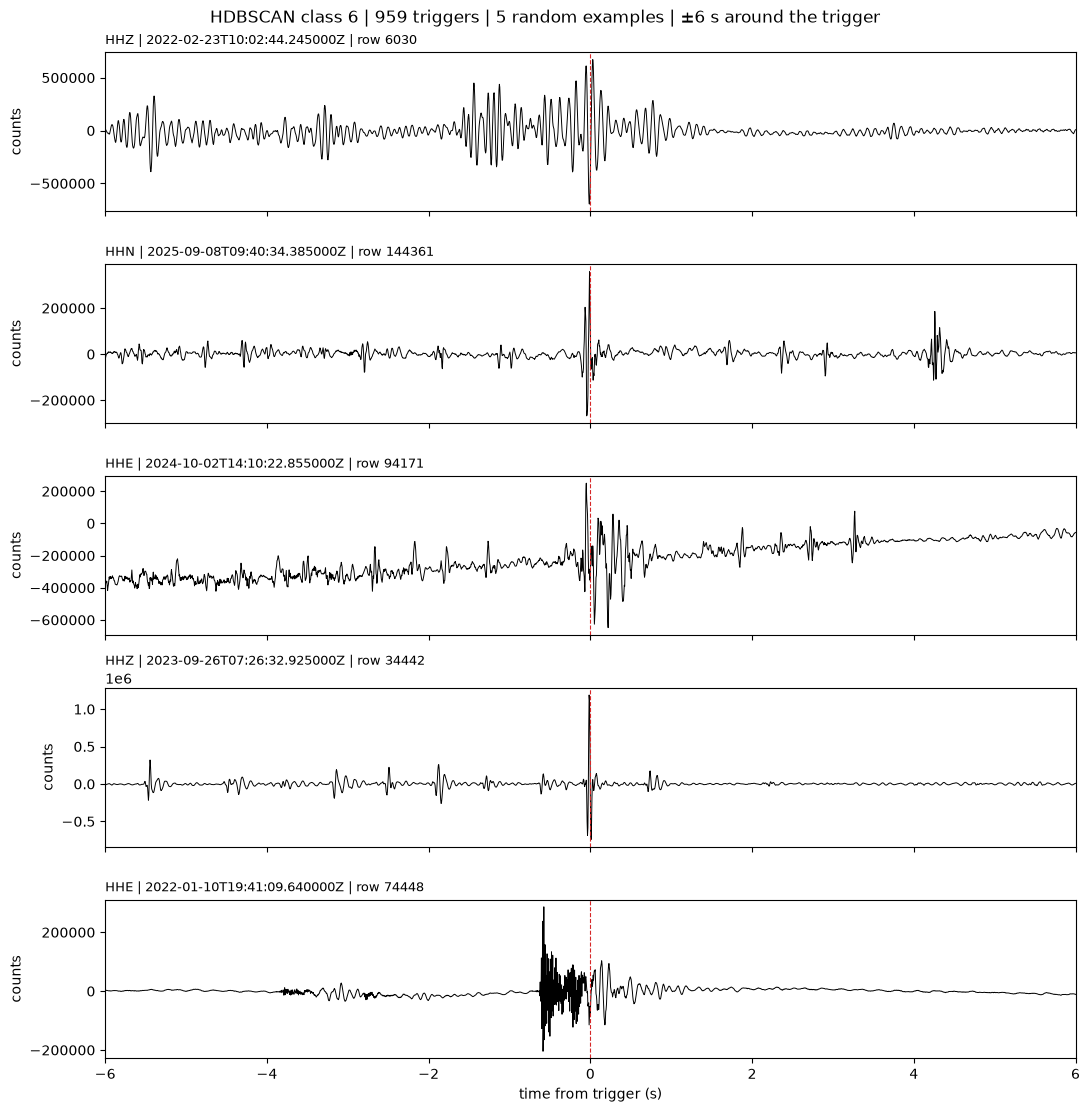

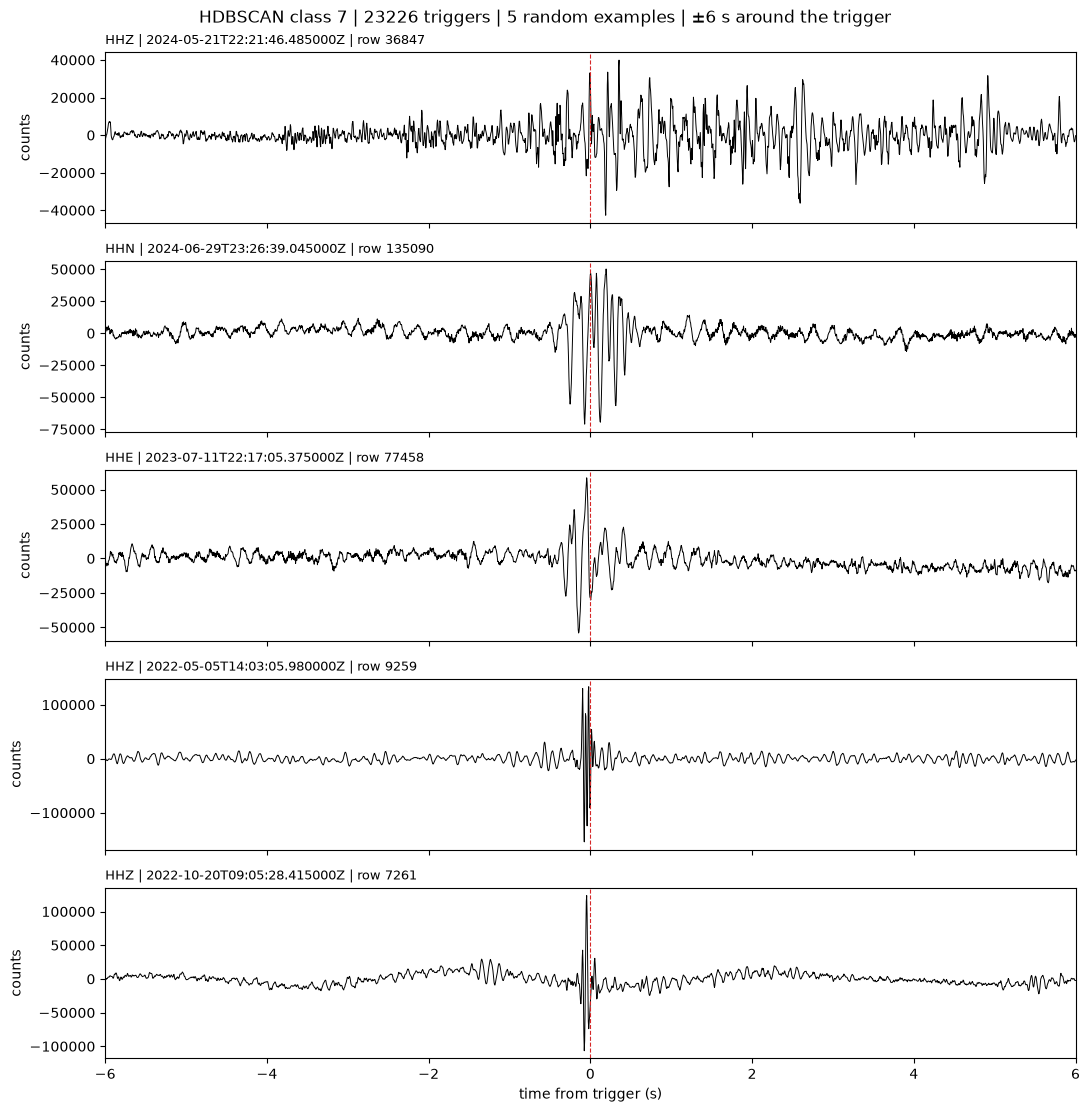

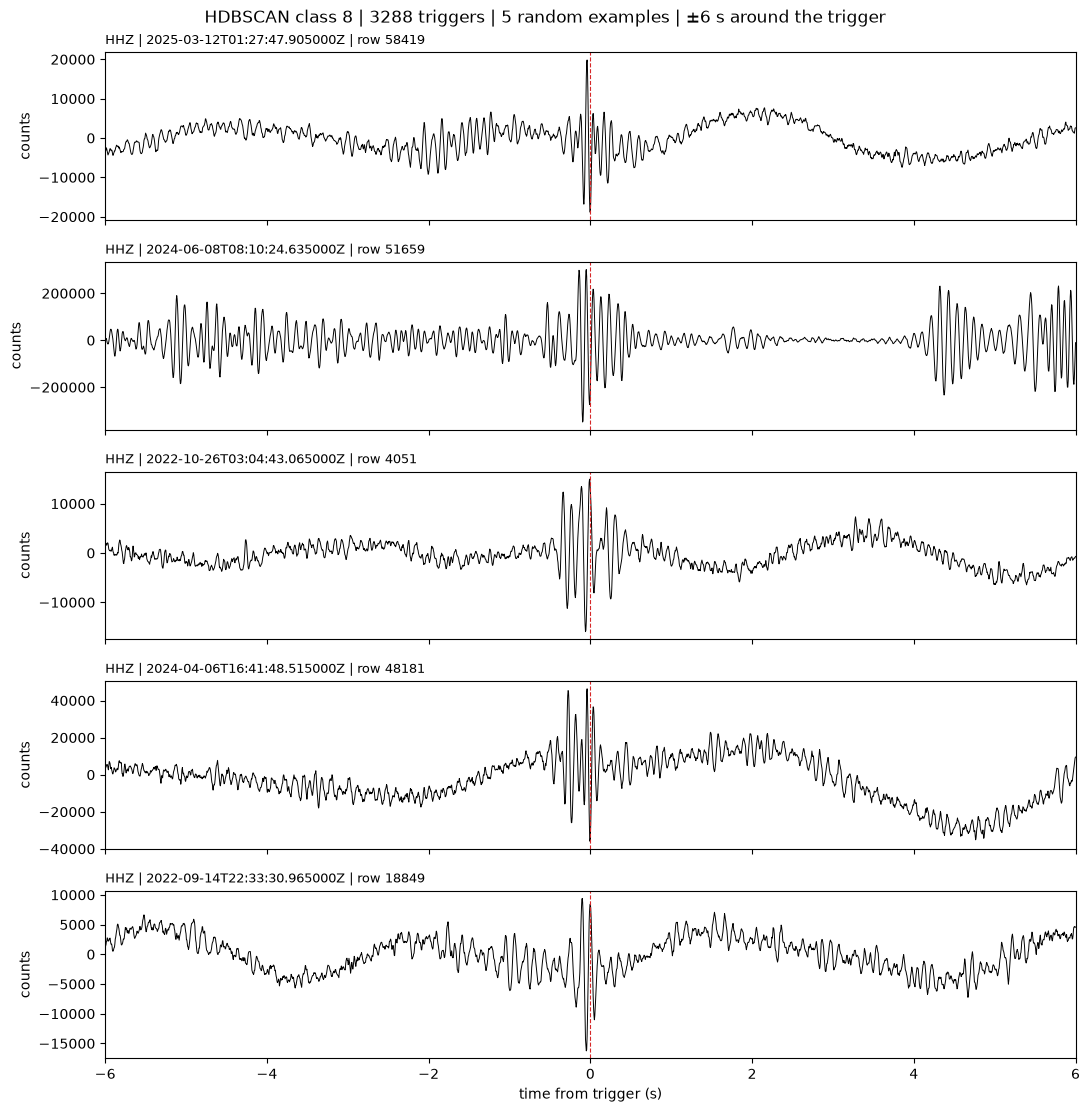

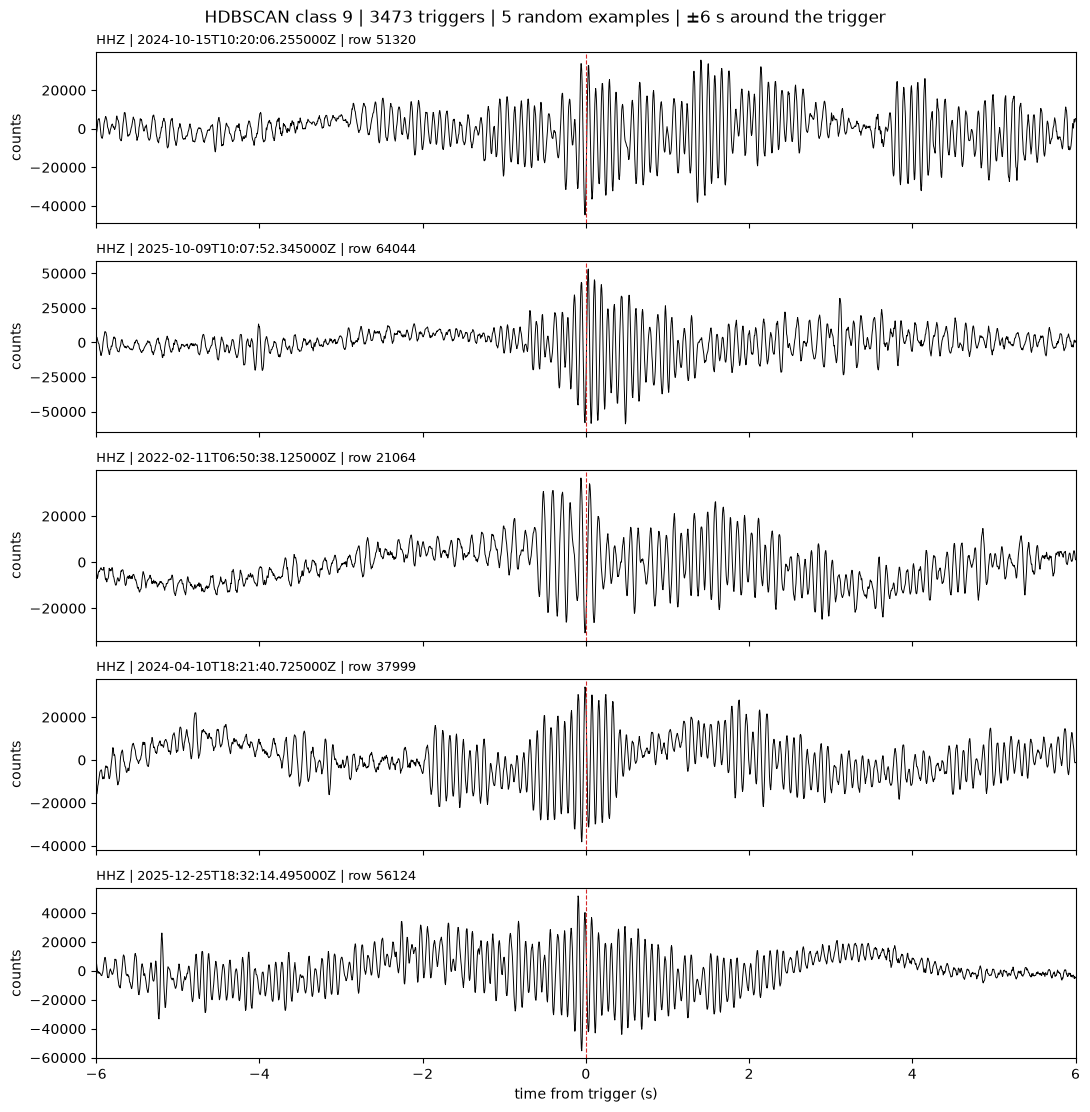

 hdbscan_class  orig_index channel year       date                trigger_time   q_value                      file
             0       50321     HHZ 2024 2024-11-20 2024-11-20T14:23:42.140000Z 23.925580 TERZ_HHZ_2024-11-20.mseed
             0       35314     HHZ 2023 2023-12-25 2023-12-25T10:06:41.900000Z 13.374806 TERZ_HHZ_2023-12-25.mseed
             0       14389     HHZ 2022 2022-05-29 2022-05-29T14:20:12.195000Z 13.374806 TERZ_HHZ_2022-05-29.mseed
             0       74838     HHE 2022 2022-03-22 2022-03-22T13:46:49.365000Z 23.925580 TERZ_HHE_2022-03-22.mseed
             0       14899     HHZ 2022 2022-01-09 2022-01-09T09:23:56.255000Z 23.925580 TERZ_HHZ_2022-01-09.mseed
             1       52614     HHZ 2024 2024-05-12 2024-05-12T05:29:39.065000Z 13.374806 TERZ_HHZ_2024-05-12.mseed
             1       54109     HHZ 2024 2024-04-30 2024-04-30T16:10:14.515000Z 13.374806 TERZ_HHZ_2024-04-30.mseed
             1       53247     HHZ 2024 2024-04-28 2024-04-28T00:22:35.315000Z 1

In [32]:
cls = df_emb["hdbscan_class"].to_numpy()
class_ids = [c for c in np.unique(cls) if INCLUDE_NOISE or c != -1]
WAVEFORM_FIG_DIR.mkdir(exist_ok=True)

# trigger_time must be an absolute time: its year has to agree with the "year" column
_chk = df_emb.sample(min(50, len(df_emb)), random_state=0)
if (pd.to_datetime(_chk["trigger_time"], utc=True).dt.year.to_numpy() != _chk["year"].astype(int).to_numpy()).mean() > 0.5:
    raise ValueError("trigger_time does not look like an absolute UTC time (its year differs from the 'year' column)")

rng = np.random.default_rng(WAVEFORM_SEED)
sample_rows = []
for c in class_ids:
    name = "noise" if c == -1 else f"class_{c}"
    items, fails = [], 0
    for i in rng.permutation(np.flatnonzero(cls == c)):       # random order; failed rows are replaced by the next one
        if len(items) >= N_PER_CLASS or fails >= 5 * N_PER_CLASS:
            break
        row = df_emb.iloc[i]
        try:
            tr, t = get_seismogram(row)
        except FileNotFoundError:
            raise                                             # fdsnws_fetch not found: no point in trying more rows
        except Exception as e:
            fails += 1
            print(f"{name}: row {i} skipped ({row['channel']} {row['trigger_time']}): {e}")
            continue
        items.append((i, tr, t))
    if not items:
        raise RuntimeError(f"{name}: no seismogram could be obtained: check MSEED_DIR, NETWORK, LOCATION and FDSNWS_FETCH")

    fig, axes = plt.subplots(len(items), 1, figsize=(11, 2.1 * len(items) + 0.8), sharex=True, squeeze=False)
    for ax, (i, tr, t) in zip(axes[:, 0], items):
        row = df_emb.iloc[i]
        ax.plot(tr.times() - (t - tr.stats.starttime), tr.data, color="k", lw=0.7)
        ax.axvline(0, color="tab:red", ls="--", lw=0.8)
        ax.set_xlim(-PLOT_HALF_WINDOW, PLOT_HALF_WINDOW)
        ax.set_ylabel("counts")
        ax.set_title(f"{row['channel']} | {row['trigger_time']} | row {i}", fontsize=9, loc="left")
        sample_rows.append({"hdbscan_class": c, "orig_index": i, "channel": row["channel"], "year": row["year"],
                            "date": row["date"], "trigger_time": row["trigger_time"], "q_value": row["q_value"], "file": row["file"]})
    axes[-1, 0].set_xlabel("time from trigger (s)")
    fig.suptitle(f"{'HDBSCAN noise' if c == -1 else f'HDBSCAN class {c}'} | {int((cls == c).sum())} triggers | "
                 f"{len(items)} random examples | ±{PLOT_HALF_WINDOW} s around the trigger")
    fig.tight_layout()
    fig.savefig(WAVEFORM_FIG_DIR / f"{name}.png", dpi=150)
    plt.show()
    plt.close(fig)

df_wave = pd.DataFrame(sample_rows)
print(df_wave.to_string(index=False))